# 01 — Linear mapping vit5-base → flan-t5-base on 100k sentence pairs

**Question.** Can a linear map from one language model's sentence representation into another's let
the second model generate a translation?

**Setup.** 97,743 train / 1,000 val / 1,000 test EN–VI pairs (`src/build_pairs.py`, seed 42).
Representation = masked-mean of the T5 encoder's last hidden state (768-d, same width on both sides).
`vit5-base` (Vietnamese) is frozen base; `flan-t5-base` carries the LoRA adapter trained in
`finetune-and-lora/` (copy circuit, 96.6 % exact copies).

**Two directions.** `f: vit5_vi → flan_en` (vi→en) and `g: flan_en → vit5_vi` (en→vi).
Both are closed-form ridge fits on 97,743 rows; λ is chosen on val.

**Why this notebook is short.** Encoding 200k sequences and generating 3,000 translations are GPU
jobs that belong in `src/encode.py` and `src/bleu.py`; the notebook reads their outputs so the
numbers here are the real ones, not a demo. Generation of the 100k training sentences is not
attempted — BLEU is measured on the 1,000-sentence test split and that limit is stated in the report.


In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as C, mapping

pd.set_option("display.width", 160)
print("root     ", ROOT.name)
print("pairs    ", C.PAIRS.name, C.PAIRS.stat().st_size // 1024, "KB")
print("results  ", sorted(p.name for p in C.RESULTS.glob("*.json")) + sorted(p.name for p in C.RESULTS.glob("*.csv")))

root      research-scale-100k
pairs     pairs_100k.parquet 11170 KB
results   ['bleu_vi_en.json', 'mapping_summary.json', 'mapping_metrics.csv', 'ridge_sweep.csv']


## 1. The data

In [2]:
meta = json.loads((C.DATA / "pairs_manifest.json").read_text())
pairs = pd.read_parquet(C.PAIRS)
print(json.dumps({k: meta[k] for k in ("rows", "split", "seed", "sha256")}, indent=2))
pairs.groupby("split").size().rename("rows").to_frame()

{
  "rows": 99743,
  "split": {
    "train": 97743,
    "val": 1000,
    "test": 1000
  },
  "seed": 42,
  "sha256": "4f1051e14bcb1193f4ba37db86e668da812d29d0419b5a67110afc4a122afe07"
}


,rows
split,
test,1000
train,97743
val,1000


In [3]:
pairs.sample(5, random_state=0)[["vi", "en"]].assign(
    vi_len=pairs["vi"].str.split().str.len(), en_len=pairs["en"].str.split().str.len())

,vi,en,vi_len,en_len
50337,"Anh có Red Bull và nửa chai Sprite, mà anh khô...","I got a Red Bull and a half a Sprite, but I ca...",17,21
438,Tuyến đường sắt cao tốc sẽ phục vụ hành khách ...,The High Speed Rail will serve passengers and ...,13,9
15711,Các hình thức tư duy theo cách của Einstein',EINSTEIN THINKING GUIDES',9,3
33211,Bây giờ tôi chắc rằng tất cả các bạn ở đây là ...,Now I'm sure all of you were the scariest mons...,23,17
40883,Ahmed Mohamed Kathrada (21 tháng 8 năm 1929-28...,Ahmed Mohamed Kathrada (21 August 1929-28 Marc...,41,27


## 2. Encoding throughput (what it actually cost)

In [4]:
enc = [json.loads((C.DATA / f"enc_{t}.json").read_text())
       for t in ("vit5_vi", "flan_en", "flan_vi_test")]
pd.DataFrame(enc)[["tag", "model", "adapter", "rows", "dim", "seconds"]].assign(
    seq_per_s=lambda d: (d.rows / d.seconds).round(1))

,tag,model,adapter,rows,dim,seconds,seq_per_s
0,vit5_vi,vit5-base,False,99743,768,118.8,839.6
1,flan_en,flan-t5-base,True,99743,768,124.8,799.2
2,flan_vi_test,flan-t5-base,True,1000,768,1.9,526.3


## 3. Fit the map and score it

`mse` and `cosine` are geometry; `retrieval@1` asks whether the mapped vector's nearest neighbour in
the target space is the same sentence. The `identity` control answers the obvious objection: how much
does the map buy over just reusing the source vector as-is?

In [5]:
summary = mapping.run()
rows = []
for d, v in summary["directions"].items():
    for tag in ("val", "test", "control_identity_test", "control_mean_test"):
        m = v[tag]
        rows.append({"direction": d, "split": tag, "lambda": v["lambda"], **m})
metrics = pd.DataFrame(rows)
metrics

{
  "pairs_sha256": "4f1051e14bcb1193f4ba37db86e668da812d29d0419b5a67110afc4a122afe07",
  "rows": {
    "train": 97743,
    "val": 1000,
    "test": 1000
  },
  "directions": {
    "vi_en": {
      "lambda": 0.0,
      "val": {
        "mse": 0.00091,
        "cosine": 0.8508,
        "retrieval_at_1": 0.509,
        "n_query": 1000,
        "n_gallery": 97743
      },
      "test": {
        "mse": 0.00088,
        "cosine": 0.8535,
        "retrieval_at_1": 0.514,
        "n_query": 1000,
        "n_gallery": 97743
      },
      "control_identity_test": {
        "mse": 0.26078,
        "cosine": 0.0083,
        "retrieval_at_1": 0.001,
        "n_query": 1000,
        "n_gallery": 97743
      },
      "control_mean_test": {
        "mse": 0.00163,
        "cosine": 0.7028,
        "retrieval_at_1": 0.0,
        "n_query": 1000,
        "n_gallery": 97743
      }
    },
    "en_vi": {
      "lambda": 0.01,
      "val": {
        "mse": 0.07221,
        "cosine": 0.8596,
        "ret

,direction,split,lambda,mse,cosine,retrieval_at_1,n_query,n_gallery
0,vi_en,val,0.00,0.00091,0.8508,0.509,1000,97743
1,vi_en,test,0.00,0.00088,0.8535,0.514,1000,97743
2,vi_en,control_identity_test,0.00,0.26078,0.0083,0.001,1000,97743
3,vi_en,control_mean_test,0.00,0.00163,0.7028,0.000,1000,97743
4,en_vi,val,0.01,0.07221,0.8596,0.515,1000,97743
5,en_vi,test,0.01,0.07018,0.8577,0.506,1000,97743
6,en_vi,control_identity_test,0.01,0.26078,0.0083,0.000,1000,97743
7,en_vi,control_mean_test,0.01,0.12161,0.7324,0.000,1000,97743


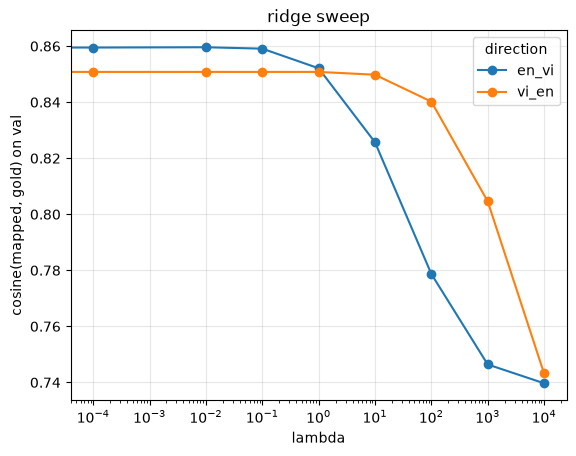

In [6]:
sweep = pd.read_csv(C.RESULTS / "ridge_sweep.csv")
ax = sweep.pivot(index="lambda", columns="direction", values="cosine").plot(
    logx=True, marker="o", ylabel="cosine(mapped, gold) on val", title="ridge sweep")
ax.grid(alpha=.3);

## 4. Does the mapped vector survive the decoder? (BLEU, vi→en)

In [7]:
bleu = json.loads((C.RESULTS / "bleu_vi_en.json").read_text())
print("test sentences:", bleu["n"], "| mean reference length: %.2f tokens" % bleu["mean_ref_tokens"])
pd.DataFrame(bleu["scores"]).T

test sentences: 1000 | mean reference length: 17.50 tokens


,bleu,chrf,empty,mean_hyp_tokens,n
mapped,0.141,4.947,14.0,22.00,1000.0
flan_encoder,3.115,10.424,0.0,15.07,1000.0
zeroshot_vit5,0.240,6.245,0.0,60.20,1000.0


`flan_encoder` is the control: flan's own encoder reads the **Vietnamese** sentence and the same
decoder generates. If `mapped` ≪ `flan_encoder`, the map is what loses the information. If both are
low, a single pooled vector is not enough for this decoder — a different conclusion entirely.

In [8]:
gens = {n: [json.loads(l) for l in (C.RESULTS / f"gen_{n}.jsonl").read_text(encoding="utf-8").splitlines()]
        for n in ("mapped", "flan_encoder", "zeroshot_vit5")}
tbl = pd.DataFrame({"vi": [g["vi"] for g in gens["mapped"]],
                    "reference": pairs[pairs.split == "test"]["en"].to_list()[:len(gens["mapped"])],
                    **{n: [g["hyp"] for g in gens[n]] for n in gens}})
tbl.head(10)

,vi,reference,mapped,flan_encoder,zeroshot_vit5
0,Anh đã thành lập một công ty để...,You've got a company set up to...,a ...,Anh thành lâp môt công ty ê...,* là dịch sang tiếng Anh.+______Z______Z______...
1,Đây là lần đầu tiên Bạch Tố Trinh làm tổn ...,"For the first time, Bai Su Zhen had harmed hum...","the ' a n a , a n , a , a , a , a , a ,",ây là lân âu tiên Bch T Trinh làm tn hi con ng...,*+_Z dịch sang tiếng Anh: Bạch Tố Trinh[] dịch...
2,e) Áp dụng chính sách như đối với kho ngoại qu...,e/To apply policies applicable to bonded wareh...,a a a a a a a a a a a a a a a a a a a a a a a ...,e) p dng chnh sách nh i vi kho ngoi quan i vi ...,* tiếng Anh:+ dịch sang tiếng Anh:_Z dịch sang...
3,Đừng ngại nhờ người khác giúp đỡ khi cần thiết.,Do not take an OTC painkiller for more than 10...,you need to a if you need a n a,ng ngi nh ngi khác gip khi cn thit.,* sang tiếng Anh: Dịch sang tiếng Anh: Dịch sa...
4,Tuy thế tôi vẫn lo sợ là lời Mab sẽ được ứng n...,"'Perhaps we should stay here for a while, Alic...",the s a n a s a t a n a t a ...,"Tuy th tôi vn lo s là li Mab s c ng nghim. "" H...","*.+__Z ""[] ""] ""! đã> tới bình minh rồi. ""j ""& ..."
5,Lützow được đặt hàng dưới tên gọi tạm thời Ers...,"Lützow was ordered as Ersatz Kaiserin Augusta,...","the s a s a s a s a , a s a , a , a , a , a , ...",Lützow c t hàng di tên gi tm thi Ersatz Kaiser...,* dịch sang tiếng Anh: Ltzow dịch sang tiếng A...
6,"Ví dụ, ở Công-gô, dựa theo cách họ đã được rèn...","So for instance, in Congo, because of how they...","the ad a , and the , and the , and the , and t...","d, Công-gô, da theo cách h c rèn luyn và tp ...",* tiếng Anh: Dịch sang tiếng Anh: Dịch sang ti...
7,""" Tài sản thừa kế của con đấy, "" mẹ cậu nói. '",""" Your inheritance, "" his mother said. '",' ' ' ' ' ' ' ' ' ' ' ' ' ' ',""" Tài sn tha k ca con y, "" m cu nói. '","*, "" mẹ cậu nói. ""+'_'Z'', "" mẹ cậu nói, "" mẹ ..."
8,""" Tao nói cho mày biết. Tại sao mày không bước...",I'll tell you what. Why dont you just get in y...,you ' a s a t a s a t a i a s a t a i a s a t ...,""" Tao nói cho mày bit. Ti sao mày không bc lên...","* mày biết."" "" Tao nói cho mày biết."" "" Tao nó..."
9,""" Show Me the Money 6 "", đã có hơn 12.000 ngườ...",""" Show Me the Money 6 "" had over 12,000 people...","the a n the a , a ...",""" Show Me the Money 6 "", có hn 12.000 ngi qua...","*"".""+""_""Z "" Show Me the Money 6 "",[ ""],! "",> ""..."


### Reading the BLEU table

Read it as a comparison, not as a translation-quality claim:

* corpus BLEU on 1,000 legal/general-domain sentences, beam = 1, no length-penalty tuning;
* the decoder sees **one pooled vector per sentence**, with no token alignment, so it cannot copy
  word order from its input. That is the architecture as proposed in `paperOverview.md` §3.3, and it
  is the main suspect if `mapped` scores poorly;
* a low score is a result about *this* representation choice (pooled encoder state, single token),
  not proof that representation mapping cannot work.